# Lab 11: Attention

**Jana Abdullah Alamer**

**2230002669**


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [1]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from google.colab import files

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [6]:
from google.colab import files
import pandas as pd

# Upload the dataset from your computer
uploaded = files.upload()

# Read the uploaded CSV file
filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

# Display dataset information
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())

display(df.head())

Saving Lab_11_QnA_Dataset.csv to Lab_11_QnA_Dataset (1).csv
Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [7]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [8]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [9]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

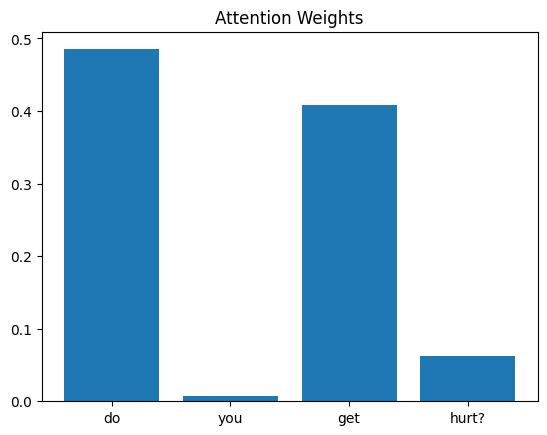

In [10]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

Question 1: do you get hurt?
Highest attention word: do
Attention weight: 0.485
----------------------------------------
Question 2: do you have fingers?
Highest attention word: do
Attention weight: 0.827
----------------------------------------
Question 3: do you ever breathe
Highest attention word: do
Attention weight: 0.700
----------------------------------------


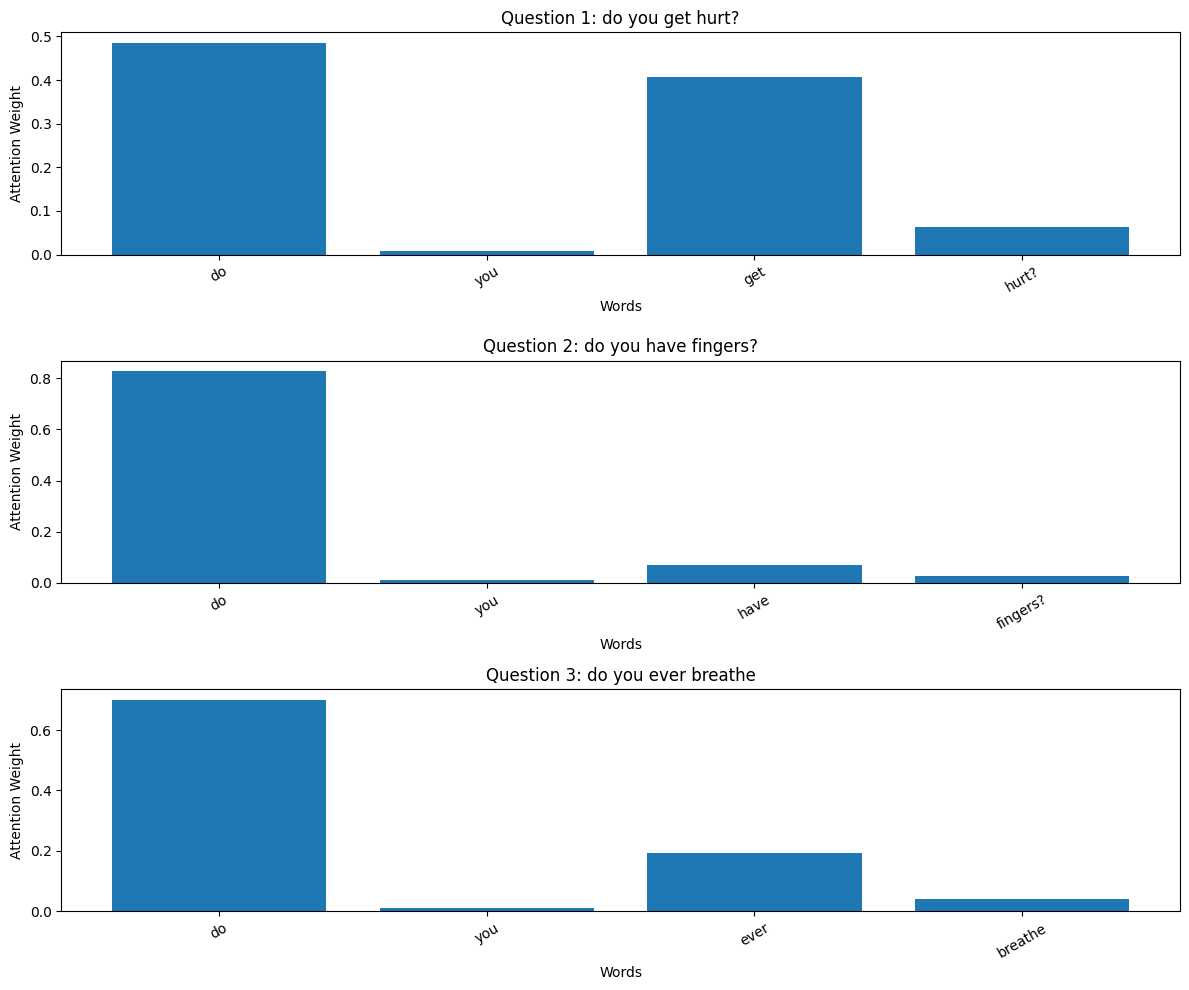

In [14]:
# Task 1 — Visualize attention for three questions

model.eval()

selected_indices = [0, 1, 2]

fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, idx in zip(axes, selected_indices):
    question = df["question"].iloc[idx]
    words = question.split()

    with torch.no_grad():
        _, weights = model(X[idx:idx + 1])

    word_weights = weights[0, :len(words)].cpu().numpy()

    ax.bar(words, word_weights)
    ax.set_title(f"Question {idx + 1}: {question}")
    ax.set_xlabel("Words")
    ax.set_ylabel("Attention Weight")
    ax.tick_params(axis="x", rotation=30)

    max_index = word_weights.argmax()

    print(f"Question {idx + 1}: {question}")
    print(f"Highest attention word: {words[max_index]}")
    print(f"Attention weight: {word_weights[max_index]:.3f}")
    print("-" * 40)

plt.tight_layout()
plt.show()

The attention weights show how the model distributes its attention across the words in each question. The word with the highest attention weight receives the most attention from the model.

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

Question 121: what do you like to be called?
Highest attention word: to
Attention weight: 0.860
Predicted class: 10
----------------------------------------
Question 125: so what do you like to be called?
Highest attention word: to
Attention weight: 0.644
Predicted class: 2
----------------------------------------
Text similarity score: 0.933


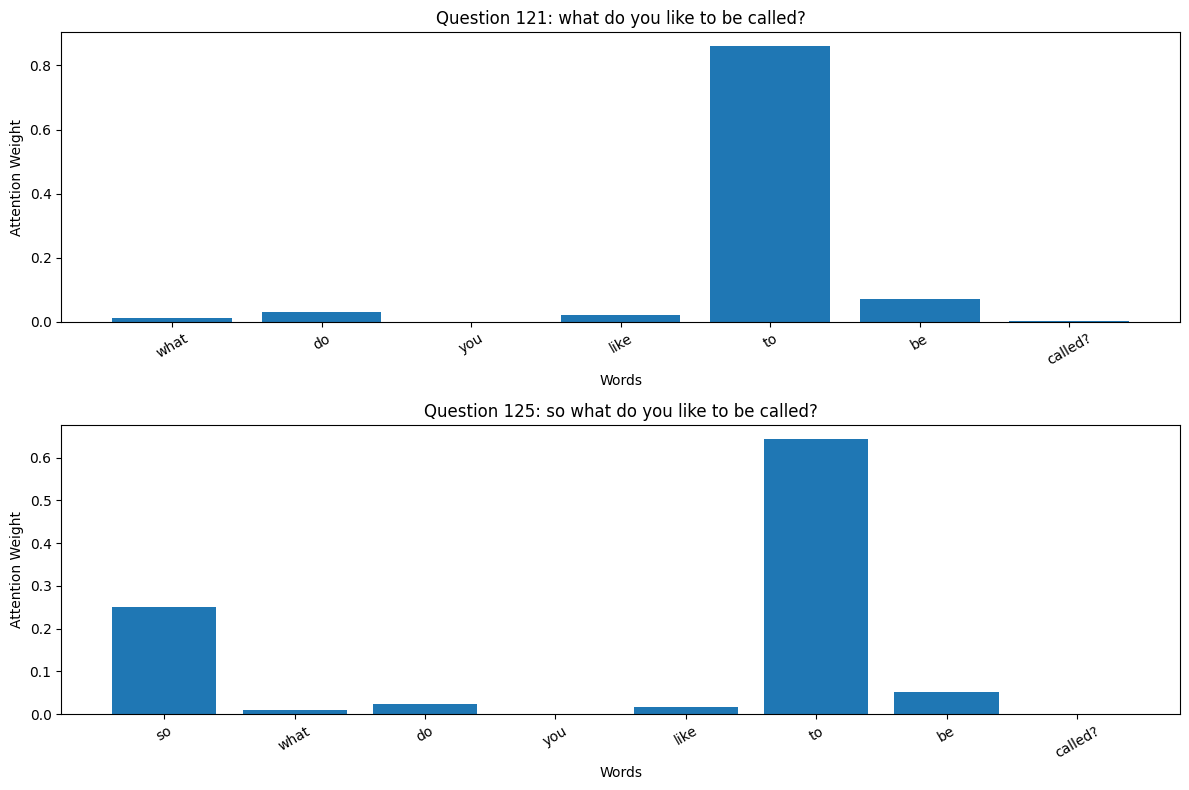

In [15]:
# Task 2 — Compare attention for similar questions

from difflib import SequenceMatcher

model.eval()

questions = df["question"].astype(str).tolist()

# Find two different questions with similar wording
best_pair = None
best_score = -1

for i in range(len(questions)):
    for j in range(i + 1, len(questions)):
        if questions[i] == questions[j]:
            continue

        score = SequenceMatcher(
            None,
            questions[i].split(),
            questions[j].split()
        ).ratio()

        if score > best_score:
            best_score = score
            best_pair = (i, j)

if best_pair is None:
    print("No two different questions found.")

else:
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    for ax, idx in zip(axes, best_pair):
        question = questions[idx]
        words = question.split()

        with torch.no_grad():
            prediction, weights = model(X[idx:idx + 1])

        word_weights = weights[0, :len(words)].cpu().numpy()
        predicted_class = prediction.argmax(dim=1).item()
        max_index = word_weights.argmax()

        ax.bar(words, word_weights)
        ax.set_title(f"Question {idx + 1}: {question}")
        ax.set_xlabel("Words")
        ax.set_ylabel("Attention Weight")
        ax.tick_params(axis="x", rotation=30)

        print(f"Question {idx + 1}: {question}")
        print(f"Highest attention word: {words[max_index]}")
        print(f"Attention weight: {word_weights[max_index]:.3f}")
        print(f"Predicted class: {predicted_class}")
        print("-" * 40)

    print(f"Text similarity score: {best_score:.3f}")

    plt.tight_layout()
    plt.show()

The two questions have similar wording and share several words. However, their attention weights differ, showing that the model can assign different levels of attention depending on the wording and context.